In [1]:
import arviz as az
import cmdstanpy

In [2]:
model = cmdstanpy.CmdStanModel(stan_file="bernoulli.stan")

In [3]:
print(model.code())

data {
  int<lower=0> N;
  array[N] int<lower=0, upper=1> y;
}
parameters {
  real<lower=0, upper=1> theta;
}
model {
  // uniform prior on interval 0,1
  theta ~ beta(1, 1);
  y ~ bernoulli(theta);
}



In [4]:
data = {
    "N": 8,
    "y": [1, 0, 0, 0, 0, 0, 1, 1],
}
samples = model.sample(data=data)

14:04:21 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

14:04:21 - cmdstanpy - INFO - CmdStan done processing.


In [11]:
model.sample?

Signature:
model.sample(
    data: Union[Mapping[str, Any], str, os.PathLike, NoneType] = None,
    chains: Optional[int] = None,
    parallel_chains: Optional[int] = None,
    threads_per_chain: Optional[int] = None,
    seed: Union[int, List[int], NoneType] = None,
    chain_ids: Union[int, List[int], NoneType] = None,
    inits: Union[Mapping[str, Any], float, str, List[str], List[Mapping[str, Any]], NoneType] = None,
    iter_warmup: Optional[int] = None,
    iter_sampling: Optional[int] = None,
    save_warmup: bool = False,
    thin: Optional[int] = None,
    max_treedepth: Optional[int] = None,
    metric: Union[str, Dict[str, Any], List[str], List[Dict[str, Any]], NoneType] = None,
    step_size: Union[float, List[float], NoneType] = None,
    adapt_engaged: bool = True,
    adapt_delta: Optional[float] = None,
    adapt_init_phase: Optional[int] = None,
    adapt_metric_window: Optional[int] = None,
    adapt_step_size: Optional[int] = None,
    fixed_param: bool = False,
    

In [5]:
samples

CmdStanMCMC: model=bernoulli chains=4['method=sample', 'algorithm=hmc', 'adapt', 'engaged=1']
 csv_files:
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/bernoulli-20250807140421_1.csv
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/bernoulli-20250807140421_2.csv
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/bernoulli-20250807140421_3.csv
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/bernoulli-20250807140421_4.csv
 output_files:
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/bernoulli-20250807140421_0-stdout.txt
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/bernoulli-20250807140421_1-stdout.txt
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/bernoulli-20250807140421_2-stdout.txt
	/var/folders/54/_lktxzc17zd8hbm440mnyjgw0000gp/T/tmp2cd81x5s/bernoulli_wfbmmf2/b

In [6]:
idata = az.from_cmdstanpy(samples)
idata

Inference data with groups:
	> posterior
	> sample_stats

In [9]:
idata.sample_stats["diverging"].sum().item()

0

In [10]:
az.summary(idata)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
theta,0.402,0.146,0.125,0.656,0.004,0.002,1639.0,2109.0,1.0


<Axes: title={'center': 'theta'}>

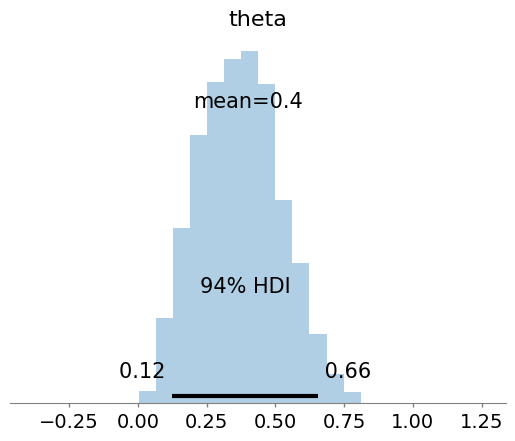

In [13]:
az.plot_posterior(idata, var_names="theta", kind="hist")

In [18]:
idata_r = az.load_arviz_data("rugby")
idata_r

Inference data with groups:
	> posterior
	> posterior_predictive
	> log_likelihood
	> log_prior
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> unconstrained_posterior

In [19]:
idata_r.posterior

<xarray.Dataset> Size: 452kB
Dimensions:    (chain: 4, draw: 500, team: 6)
Coordinates:
  * chain      (chain) int64 32B 0 1 2 3
  * draw       (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
  * team       (team) <U8 192B 'Wales' 'France' 'Ireland' ... 'Italy' 'England'
Data variables:
    home       (chain, draw) float64 16kB ...
    intercept  (chain, draw) float64 16kB ...
    atts_star  (chain, draw, team) float64 96kB ...
    defs_star  (chain, draw, team) float64 96kB ...
    sd_att     (chain, draw) float64 16kB ...
    sd_def     (chain, draw) float64 16kB ...
    atts       (chain, draw, team) float64 96kB ...
    defs       (chain, draw, team) float64 96kB ...
Attributes:
    created_at:                 2024-03-06T20:46:23.841916
    arviz_version:              0.17.0
    inference_library:          pymc
    inference_library_version:  5.10.4+7.g34d2a5d9
    sampling_time:              8.503105401992798
    tuning_steps:               1000

In [25]:
idata_r.posterior["atts"].mean(dim=["chain", "draw"]).to_series()

team
Wales       0.170448
France     -0.084249
Ireland     0.107084
Scotland   -0.115415
Italy      -0.334736
England     0.256867
Name: atts, dtype: float64

In [ ]:
idata_r.posterior["atts"].mean(dim=["chain", "draw"]).to_series()

In [29]:
idata_r.posterior["atts"].quantile([0.01, 0.99], dim=["chain", "draw"]).to_series().unstack("quantile").sort_values(0.01)

quantile,0.01,0.99
team,,
Italy,-0.467271,-0.210223
Scotland,-0.221220,-0.010549
France,-0.187589,0.016192
Ireland,0.006920,0.208026
Wales,0.070771,0.277612
England,0.162445,0.351138


In [34]:
att_diff_scotland_minus_france = (
    idata_r.posterior["atts"].sel(team="Scotland")
    - idata_r.posterior["atts"].sel(team="France")
)
(att_diff_scotland_minus_france > 0).mean().item()

0.317

In [30]:
idata_r.posterior["defs"].quantile([0.01, 0.99], dim=["chain", "draw"]).to_series().unstack("quantile").sort_values(0.01)

quantile,0.01,0.99
team,,
Ireland,-0.515133,-0.271501
England,-0.324249,-0.085750
Wales,-0.240973,-0.016229
France,-0.142426,0.062632
Scotland,0.074690,0.269629
Italy,0.495503,0.664307


In [35]:
az.summary(idata)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
theta,0.402,0.146,0.125,0.656,0.004,0.002,1639.0,2109.0,1.0
